# A3b — Split aleatório 70-15-15 (2019–2025) e cenário sem 2020–2021

**Pessoa A (apoio ao A3).** Experimento **comparativo**: o projeto usa validação temporal como padrão; aqui medimos o que muda com um **split aleatório estratificado 70/15/15** e quando **2020 e 2021** (anos de pandemia) saem da base.

| Cenário | Anos (de `DT_INTERNA`) | Split |
|---|---|---|
| `todos_2019_2025` | 2019–2025 | aleatório 70/15/15, estratificado pelo alvo, seed 42 |
| `sem_2020_2021` | 2019, 2022–2025 | idem |

**Saídas** (em `data/analytical/`, `outputs/tables/pessoa_a/` e `outputs/figures/pessoa_a/`):
- `dataset_supervisionado_<cenário>.parquet` com a coluna **`split`** (`treino` / `validacao` / `holdout`) e `.meta.json` (versão, SHA-256, contagens).
- Tabelas de proporções, prevalência e anos por split; waterfall por cenário.
- **Gráficos (PNG)**: proporções 70/15/15, prevalência de óbito por split e composição dos splits por ano (`split_<cenário>.png`); comparação dos cenários (`split_comparacao_cenarios.png`).
- Benchmark rápido (regressão logística, treino → **validação**): split aleatório × temporal por ordem.

> O **holdout não é aberto** aqui (regra do projeto). O benchmark usa só treino e validação.
> Os dois datasets **não substituem** `dataset_supervisionado.parquet` (o do pipeline temporal do C2).

In [1]:
# ----- Setup (não editar) -----
import os, sys
from pathlib import Path

# PKG_ROOT: pasta que contém src/protocolo (onde o pacote foi copiado)
# REPO_ROOT: raiz do repositório (tem .git ou data/); é de onde lemos dados e gravamos saídas
_parents = [Path.cwd(), *Path.cwd().parents]
PKG_ROOT = next((p for p in _parents if (p / "src" / "protocolo").exists()), None)
if PKG_ROOT is None:
    raise FileNotFoundError(
        "Pasta src/protocolo não encontrada acima de " + str(Path.cwd()) + ". "
        "Copie 'src/protocolo/' do pacote para o 'src/' do repositório "
        "(deve existir src/protocolo/verificacoes.py) e rode a célula de novo.")
REPO_ROOT = next((p for p in _parents if (p / ".git").exists() or (p / "data").exists()), PKG_ROOT)
os.chdir(REPO_ROOT); sys.path.insert(0, str(PKG_ROOT))

# Proteção contra outro pacote chamado 'src' (ex.: instalado por pip) ou 'src' antigo em cache no kernel:
# um pacote regular em qualquer ponto do sys.path vence um 'src' sem __init__.py.
for _m in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]
_init = PKG_ROOT / "src" / "__init__.py"
if not _init.exists():
    _init.touch()
    print("Criado", _init, "(torna o src do projeto um pacote regular)")

import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print
from src.protocolo import verificacoes as v
if getattr(v, "MODULE_VERSION", "0") < "0.8":
    raise RuntimeError(
        "src/protocolo/verificacoes.py está desatualizado (versão " + str(getattr(v, "MODULE_VERSION", "antiga")) + "). "
        "Substitua pelo arquivo do pacote novo e REINICIE o kernel (o Python mantém o módulo antigo em cache).")

# ----- Parâmetros -----
USAR_DEMO = False                       # True = dados sintéticos só para testar o notebook
DATA_PATH = None                        # None = procura Parquet/CSV em data/ ; ou informe o caminho do arquivo
SAMPLE = 0                              # ex.: 200_000 para execução rápida
OUT = "outputs/tables/pessoa_a"         # saídas (tabelas, atas, decisões), relativas à raiz do repositório
CFG_PATH = next((str(p) for p in [REPO_ROOT / "configs" / "decisoes.yaml", PKG_ROOT / "configs" / "decisoes.yaml"]
                 if p.exists()), "configs/decisoes.yaml")
SUPERVISED_CONFIG = "configs/supervised.yaml"   # config do C (alvo, features, coluna_tempo)
COLUNAS = "minimas"                   # "minimas" (menos memória) | "classificadas" | "todas" (pesado!) | lista de nomes
CENARIOS = None                     # None = usa configs/decisoes.yaml -> experimentos_split.cenarios
                                    # ou informe, ex.: {"todos_2019_2025": [2019, 2020, 2021, 2022, 2023, 2024, 2025]}
RODAR_BENCHMARK = True              # regressão logística treino -> validação (aleatório x temporal)
FIG_DIR = "outputs/figures/pessoa_a"  # onde salvar os gráficos (PNG)
print("Raiz do repositório:", REPO_ROOT)
print("Pacote (src/protocolo):", PKG_ROOT)
print("Config de decisões:", CFG_PATH)
cfg = v.load_config(CFG_PATH)
rep = v.Report(OUT, "relatorio_A3b")
df = v.prepare(v.carregar_base(DATA_PATH, USAR_DEMO, SAMPLE, COLUNAS, cfg, SUPERVISED_CONFIG))
print(f"Memória do DataFrame: {v.uso_memoria_gb(df):.2f} GB")

Raiz do repositório: c:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador
Pacote (src/protocolo): c:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador
Config de decisões: c:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\configs\decisoes.yaml
[base] C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\data\processed\dados-v2\srag.parquet -> 4,666,910 linhas x 54 colunas carregadas (de 198 no arquivo) | leitura compacto (texto em category)
Memória do DataFrame: 0.58 GB


## 1. Cenários
Os anos vêm do `configs/decisoes.yaml` (`experimentos_split.cenarios`); a seed e as frações também.

In [2]:
e = cfg["experimentos_split"]
CENARIOS = CENARIOS or {nome: spec["anos"] for nome, spec in e["cenarios"].items()}
print("Seed:", e["seed"], "| frações:", e["fracoes"], "| estratificado pelo alvo:", e["estratificar_por_alvo"])
for nome, anos in CENARIOS.items():
    print(f"  {nome}: {anos}")
anos_na_base = sorted(v.parse_date(df[cfg["cols"]["dt_interna"]]).dt.year.dropna().astype(int).unique())
print("Anos de DT_INTERNA presentes na base carregada:", anos_na_base)

Seed: 42 | frações: {'treino': 0.7, 'validacao': 0.15, 'holdout': 0.15} | estratificado pelo alvo: True
  todos_2019_2025: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
  sem_2020_2021: [2019, 2022, 2023, 2024, 2025]
Anos de DT_INTERNA presentes na base carregada: [np.int64(1917), np.int64(1918), np.int64(1941), np.int64(2009), np.int64(2011), np.int64(2012), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026), np.int64(2027), np.int64(2028), np.int64(2029), np.int64(2031), np.int64(2032), np.int64(2033), np.int64(2034), np.int64(2050), np.int64(2052), np.int64(2055), np.int64(2056), np.int64(2092), np.int64(2098), np.int64(2099)]


## 2. Coorte, dataset e checagens por cenário
Waterfall do cenário → dataset com `split` → proporções 70/15/15, estratificação do alvo, anos em cada split, `NU_NOTIFIC` repetido entre splits e contrato do C2.


===== todos_2019_2025: [2019, 2020, 2021, 2022, 2023, 2024, 2025] =====
[ok] A1 | Waterfall da coorte [todos_2019_2025]: 4,666,910 -> 3,739,615 registros (80.1%)
[ok] A1 | Features derivadas [todos_2019_2025]: criadas no dataset: idade_anos, faixa_etaria
[!!] A1 | Dataset analítico [todos_2019_2025]: 3,739,615 linhas v0.1; features ausentes na base: DIAS_SINTOMAS_ATE_INTERNACAO, SEXO_CATEGORIA
[ok] A3b | Proporções 70/15/15 [todos_2019_2025]: desvio máximo 0.00 p.p. | treino=2,617,730, validacao=560,942, holdout=560,943
[ok] A3b | Estratificação do alvo [todos_2019_2025]: prevalência de óbito por split: treino=22.63%, validacao=22.63%, holdout=22.63% (amplitude 0.00 p.p.)
[ok] A3b | Anos em cada split [todos_2019_2025]: todos os anos aparecem nos 3 splits (split aleatório mistura os períodos)
[!!] A3b | NU_NOTIFIC entre splits [todos_2019_2025]: 10 NU_NOTIFIC aparecem em mais de um split (pode ser vazamento entre treino e validação)
[XX] A1-C2 | Colunas exigidas pelo C2: ausentes no d

,ordem,filtro,regra,n_excluido,n_restante,pct_restante
0,0,Base completa,—,0,4666910,100.00
1,1,Hospitalização confirmada,HOSPITAL = 1,232253,4434657,95.02
2,2,Data de internação válida,"DT_INTERNA parseável, ≥ 2009-01-01 e ≤ hoje",72133,4362524,93.48
3,3,Período analítico,"ano(DT_INTERNA) em [2019, 2020, 2021, 2022, 20...",210444,4152080,88.97
4,4,Evolução encerrada,"EVOLUCAO em ['1', '2', '3'] (9/ausente fora)",338815,3813265,81.71
5,5,Alvo binário definido,"EVOLUCAO em {cura, óbito}; óbito por outras ca...",73650,3739615,80.13


,split,n,n_obitos,pct_linhas,prevalencia_obito_pct
0,treino,2617730,592509,70.0,22.63
1,validacao,560942,126966,15.0,22.63
2,holdout,560943,126967,15.0,22.63


,ano_internacao,treino,validacao,holdout
0,2019,30393,6694,6426
1,2020,686366,146395,147051
2,2021,1036718,221925,221572
3,2022,332754,71549,71677
4,2023,168742,36006,35956
5,2024,160515,34358,34605
6,2025,202242,44015,43656


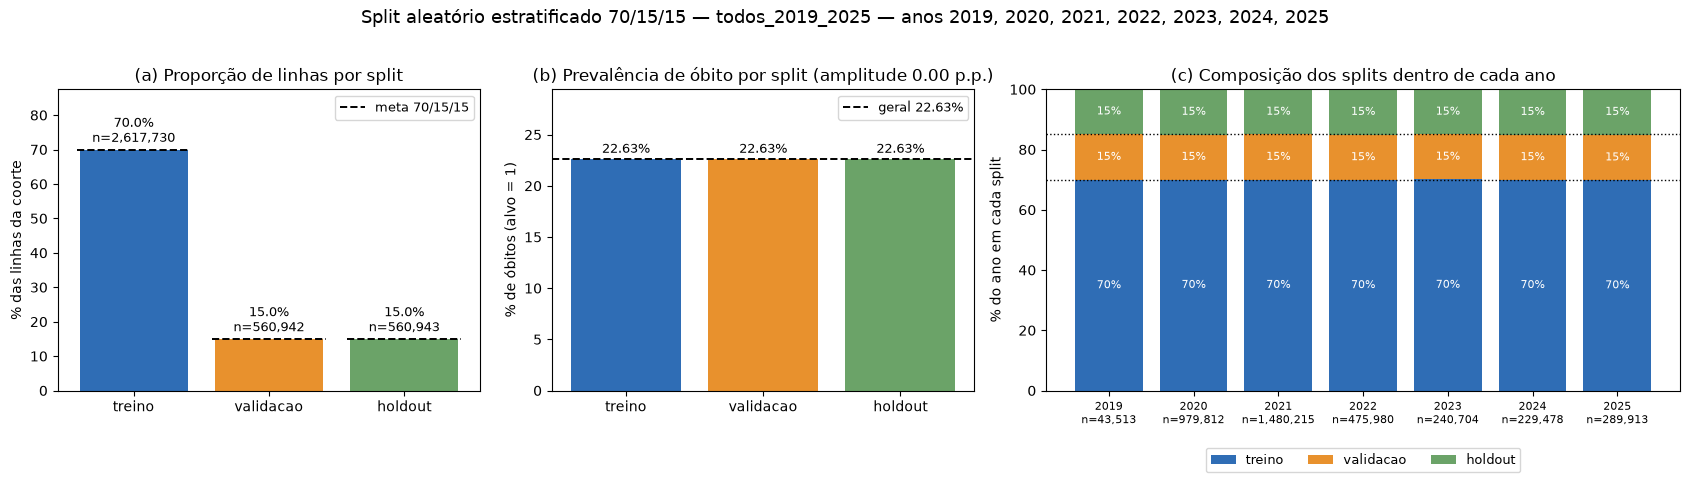

Figura: outputs\figures\pessoa_a\split_todos_2019_2025.png

===== sem_2020_2021: [2019, 2022, 2023, 2024, 2025] =====
[ok] A1 | Waterfall da coorte [sem_2020_2021]: 4,666,910 -> 1,279,588 registros (27.4%)
[ok] A1 | Features derivadas [sem_2020_2021]: criadas no dataset: idade_anos, faixa_etaria
[!!] A1 | Dataset analítico [sem_2020_2021]: 1,279,588 linhas v0.1; features ausentes na base: DIAS_SINTOMAS_ATE_INTERNACAO, SEXO_CATEGORIA
[ok] A3b | Proporções 70/15/15 [sem_2020_2021]: desvio máximo 0.00 p.p. | treino=895,712, validacao=191,938, holdout=191,938
[ok] A3b | Estratificação do alvo [sem_2020_2021]: prevalência de óbito por split: treino=12.12%, validacao=12.12%, holdout=12.12% (amplitude 0.00 p.p.)
[ok] A3b | Anos em cada split [sem_2020_2021]: todos os anos aparecem nos 3 splits (split aleatório mistura os períodos)
[!!] A3b | NU_NOTIFIC entre splits [sem_2020_2021]: 9 NU_NOTIFIC aparecem em mais de um split (pode ser vazamento entre treino e validação)
[XX] A1-C2 | Colunas exi

,ordem,filtro,regra,n_excluido,n_restante,pct_restante
0,0,Base completa,—,0,4666910,100.00
1,1,Hospitalização confirmada,HOSPITAL = 1,232253,4434657,95.02
2,2,Data de internação válida,"DT_INTERNA parseável, ≥ 2009-01-01 e ≤ hoje",72133,4362524,93.48
3,3,Período analítico,"ano(DT_INTERNA) em [2019, 2022, 2023, 2024, 2025]",2944197,1418327,30.39
4,4,Evolução encerrada,"EVOLUCAO em ['1', '2', '3'] (9/ausente fora)",101808,1316519,28.21
5,5,Alvo binário definido,"EVOLUCAO em {cura, óbito}; óbito por outras ca...",36931,1279588,27.42


,split,n,n_obitos,pct_linhas,prevalencia_obito_pct
0,treino,895712,108527,70.0,12.12
1,validacao,191938,23256,15.0,12.12
2,holdout,191938,23255,15.0,12.12


,ano_internacao,treino,validacao,holdout
0,2019,30412,6546,6555
1,2022,333642,71094,71244
2,2023,168213,36176,36315
3,2024,160377,34741,34360
4,2025,203068,43381,43464


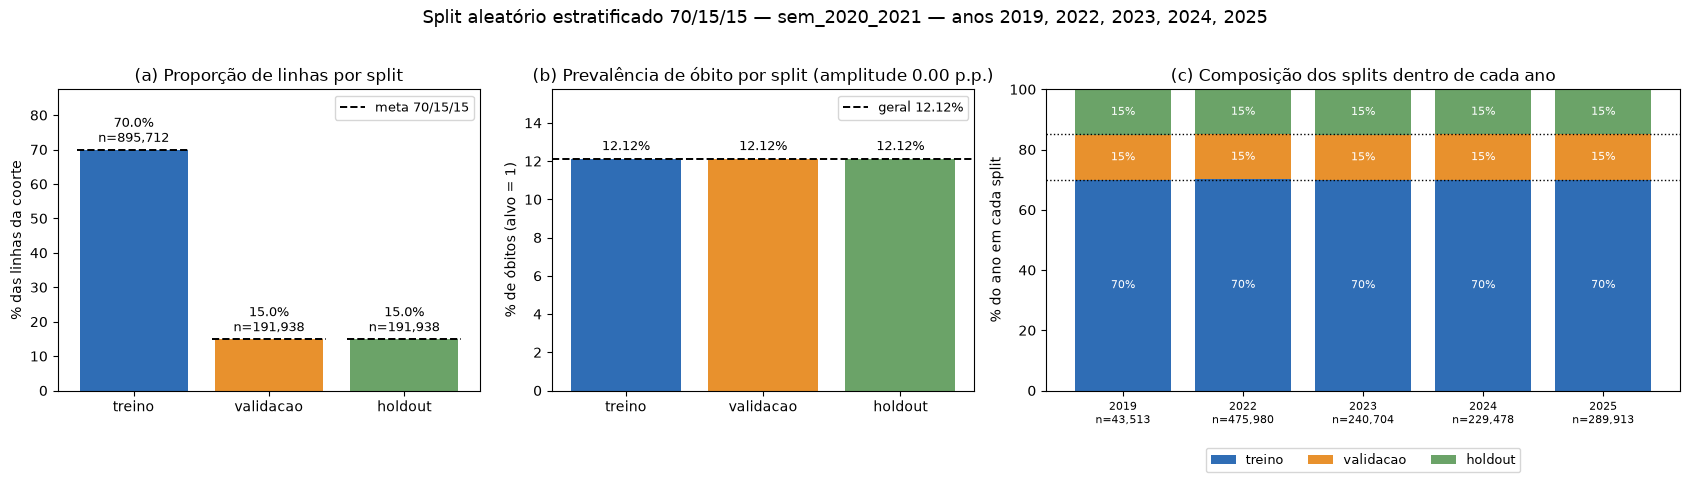

Figura: outputs\figures\pessoa_a\split_sem_2020_2021.png


In [3]:
metas = {}
for nome, anos in CENARIOS.items():
    print(f"\n===== {nome}: {anos} =====")
    metas[nome] = v.a3_split_aleatorio_cenario(df, cfg, rep, nome, anos, SUPERVISED_CONFIG)
    v.validar_contrato_c2(metas[nome]["arquivo"], SUPERVISED_CONFIG, rep)
    display(pd.read_csv(Path(OUT) / f"a1_waterfall_{nome}.csv"))
    display(pd.read_csv(Path(OUT) / f"a3_split_aleatorio_{nome}.csv"))
    display(pd.read_csv(Path(OUT) / f"a3_split_aleatorio_{nome}_por_ano.csv"))
    # (a) % de linhas x meta 70/15/15 | (b) prevalência de óbito por split | (c) composição dos splits em cada ano
    print("Figura:", v.grafico_split_cenario(rep, cfg, nome, anos, FIG_DIR, mostrar=True))

## 3. Benchmark: split aleatório × temporal (treino → validação)
Regressão logística balanceada, mesmas features do `supervised.yaml`. Se o aleatório der PR-AUC maior que o temporal, ele está **otimista** (registros do mesmo período nos dois lados): a decisão deve seguir o temporal.

In [4]:
benchs = {}
if RODAR_BENCHMARK:
    for nome in CENARIOS:
        benchs[nome] = v.a3_benchmark_split(metas[nome]["arquivo"], SUPERVISED_CONFIG, cfg, rep, nome,
                                            max_rows=e["bench_max_linhas"], seed=e["seed"])
        display(benchs[nome])
else:
    print("Benchmark desligado (RODAR_BENCHMARK = False).")

[!!] A3b | Split aleatório x temporal [todos_2019_2025]: PR-AUC (validação): aleatório 0.452 vs temporal 0.364 (Δ +0.087) — o aleatório está otimista; decidir pelo temporal


,cenario,particao,n_treino,n_validacao,prevalencia_validacao,modelo,roc_auc,pr_auc,brier
0,todos_2019_2025,aleatoria,139616,30329,0.2309,baseline_prior,0.5000,0.2309,0.1776
1,todos_2019_2025,aleatoria,139616,30329,0.2309,logistica,0.7740,0.4517,0.1984
2,todos_2019_2025,temporal_por_ordem,139803,30142,0.1377,baseline_prior,0.5000,0.1377,0.1383
3,todos_2019_2025,temporal_por_ordem,139803,30142,0.1377,logistica,0.8206,0.3642,0.1678


[!!] A3b | Split aleatório x temporal [sem_2020_2021]: PR-AUC (validação): aleatório 0.367 vs temporal 0.276 (Δ +0.091) — o aleatório está otimista; decidir pelo temporal


,cenario,particao,n_treino,n_validacao,prevalencia_validacao,modelo,roc_auc,pr_auc,brier
0,sem_2020_2021,aleatoria,139939,30227,0.1194,baseline_prior,0.5000,0.1194,0.1051
1,sem_2020_2021,aleatoria,139939,30227,0.1194,logistica,0.8371,0.3670,0.1739
2,sem_2020_2021,temporal_por_ordem,139890,29922,0.0766,baseline_prior,0.5000,0.0766,0.0747
3,sem_2020_2021,temporal_por_ordem,139890,29922,0.0766,logistica,0.8418,0.2763,0.1390


## 4. Comparação entre os cenários

,cenario,anos,n_linhas,n_obitos,prevalencia_obito_pct,pr_auc_aleatoria,roc_auc_aleatoria,pr_auc_temporal_por_ordem,roc_auc_temporal_por_ordem
0,todos_2019_2025,"2019,2020,2021,2022,2023,2024,2025",3739615,846442,22.63,0.4517,0.7740,0.3642,0.8206
1,sem_2020_2021,"2019,2022,2023,2024,2025",1279588,155038,12.12,0.3670,0.8371,0.2763,0.8418


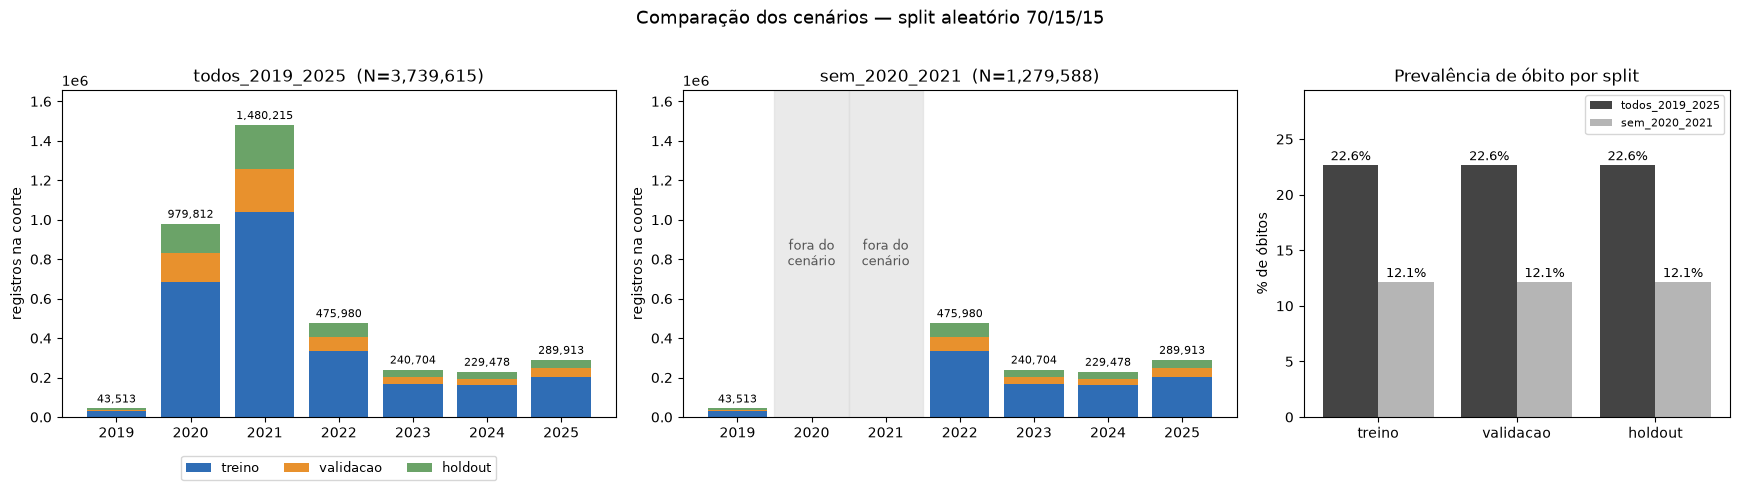

Figura: outputs\figures\pessoa_a\split_comparacao_cenarios.png


In [5]:
comp = v.comparar_cenarios(metas, benchs, rep)
display(comp)
# N por ano (empilhado por split) nos dois cenários + prevalência de óbito por split
print("Figura:", v.grafico_comparacao_cenarios(rep, cfg, list(CENARIOS), FIG_DIR, mostrar=True))

## 5. Decisões

In [6]:
E = "A3b"
v.log_decision(OUT, "D-13", "Experimento split aleatório 70/15/15 (2019–2025)",
               f"Split aleatório estratificado pelo alvo, seed {e['seed']}; dataset_supervisionado_todos_2019_2025", E,
               impacto="Comparativo; o padrão do projeto segue a validação temporal (README)",
               evidencia="a3_benchmark_split_*.csv")
v.log_decision(OUT, "D-14", "Cenário sem 2020 e 2021",
               "Mesma análise removendo 2020–2021 (pandemia); dataset_supervisionado_sem_2020_2021", E,
               impacto="Compara N, prevalência e desempenho com a base completa (comparacao_cenarios.csv)")
display(pd.read_csv(Path(OUT) / "tabela_decisoes.csv"))

,id,etapa,tema,decisao,responsavel,data,status,impacto,evidencia
0,D-01,A1,Ponto de previsão,DT_INTERNA (admissão); campos posteriores bloq...,Pessoa A,2026-10-16,proposta,Define quais variáveis podem entrar,Dicionário SIVEP-Gripe (completar)
1,D-02,A1,Coorte estrita,"HOSPITAL=1, DT_INTERNA válida, período analíti...",Pessoa A,2026-10-16,proposta,Ver waterfall (a1_waterfall.csv),NaN
2,D-03,A1,Alvo principal,Óbito SRAG (EVOLUCAO=2) vs cura (EVOLUCAO=1),Pessoa A,2026-10-16,proposta,Alinhar target.positivos do supervised.yaml (G1),NaN
3,D-04,A1,Evolução desconhecida e óbito outras causas,EVOLUCAO=9/ausente e 3 saem do alvo binário; n...,Pessoa A,2026-10-16,proposta,"Exigir filtro EVOLUCAO in {1,2} no loader do C",NaN
4,D-12,A1,Features derivadas (criadas no dataset analítico),"idade_anos (TP_IDADE), faixa_etaria, intervalo...",Pessoa A,2026-10-16,proposta,Só informação da admissão; o C2 as encontra no...,NaN
5,D-05,A1,Período analítico,"Desenvolvimento [2022, 2023, 2024]; holdout [2...",Pessoa A,2026-10-16,proposta,Exclui anos fora do período; alinhar G2,NaN
6,D-06,A2,Ação por tipo de inconsistência de datas,Nascimento posterior ao início dos sintomas ->...,Pessoa A,2026-10-16,proposta,Ver a2_coerencia_datas.csv,NaN
7,D-07,A2,Duplicidades,Linhas exatas removidas; NU_NOTIFIC repetido a...,Pessoa A,2026-10-16,proposta,Ver a2_duplicidades.csv,NaN
8,D-08,A2,Maturidade de EVOLUCAO,Meses do holdout com < 90.0% de evolução fecha...,Pessoa A,2026-10-16,proposta,Ver a2_maturidade_evolucao_por_mes.csv,NaN
9,D-09,A2,Variáveis proibidas/condicionais,Matriz de elegibilidade v1.0 (classes incluir/...,Pessoa A,2026-10-16,proposta,C bloqueia automaticamente (test_leakage); B u...,NaN


## 6. Fechamento

In [7]:
path = rep.write_md()
print("Relatório:", path)
display(pd.DataFrame(rep.findings, columns=["etapa", "verificação", "status", "detalhe"]))

Relatório: outputs\tables\pessoa_a\relatorio_A3b.md


,etapa,verificação,status,detalhe
0,A1,Waterfall da coorte [todos_2019_2025],OK,"4,666,910 -> 3,739,615 registros (80.1%)"
1,A1,Features derivadas [todos_2019_2025],OK,"criadas no dataset: idade_anos, faixa_etaria"
2,A1,Dataset analítico [todos_2019_2025],ATENÇÃO,"3,739,615 linhas v0.1; features ausentes na ba..."
3,A3b,Proporções 70/15/15 [todos_2019_2025],OK,"desvio máximo 0.00 p.p. | treino=2,617,730, va..."
4,A3b,Estratificação do alvo [todos_2019_2025],OK,"prevalência de óbito por split: treino=22.63%,..."
5,A3b,Anos em cada split [todos_2019_2025],OK,todos os anos aparecem nos 3 splits (split ale...
6,A3b,NU_NOTIFIC entre splits [todos_2019_2025],ATENÇÃO,10 NU_NOTIFIC aparecem em mais de um split (po...
7,A1-C2,Colunas exigidas pelo C2,FALHA,ausentes no dataset: dias_sintomas_ate_interna...
8,A1-C2,Coluna de tempo,OK,"datetime válido, ordenado: 2019-01-01 -> 2025-..."
9,A1-C2,Alvo,OK,apenas cura/óbito; positivos [2.0] presentes


### Como o C pode usar a coluna `split`
O C2 atual divide por frações no tempo (`TemporalSplit`). Para usar o split aleatório, basta ler o dataset do cenário e filtrar pela coluna:

```python
df = pd.read_parquet(C.ANALYTICAL_DIR / "dataset_supervisionado_todos_2019_2025.parquet")
treino, validacao, holdout = (df[df["split"] == s] for s in ("treino", "validacao", "holdout"))
```

### Checklist
- [ ] Proporções 70/15/15 e prevalência de óbito iguais entre os splits (estratificação)
- [ ] Comparação aleatório × temporal interpretada (otimismo do aleatório)
- [ ] Comparação com e sem 2020–2021 registrada (N, prevalência, desempenho)
- [ ] Holdout **não** aberto